# A/B Testing
### Data Science Core Concepts 101 — by Yunhan Jin

A/B testing (also called controlled experiments or randomized experiments) is the gold standard for measuring the causal impact of a change. Users are randomly split into two groups:
- **Control (A)**: the current version
- **Treatment (B)**: the new version

By randomizing assignment, we isolate the effect of the change from all other factors.

---

## Section 1: Setup
We simulate an e-commerce A/B test: a new checkout page design is tested against the current one.

Two metrics are tracked per user:
- `converted` — did the user complete a purchase? (binary)
- `revenue` — how much did they spend? (continuous, 0 if not converted)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n_per_group = 1000

# Control group (A) — current checkout
control_converted = np.random.binomial(1, 0.10, n_per_group)
control_revenue   = np.where(
    control_converted,
    np.random.normal(50, 15, n_per_group).clip(5),
    0
)

# Treatment group (B) — new checkout design
treatment_converted = np.random.binomial(1, 0.12, n_per_group)
treatment_revenue   = np.where(
    treatment_converted,
    np.random.normal(53, 15, n_per_group).clip(5),
    0
)

df = pd.DataFrame({
    'group':     ['control'] * n_per_group + ['treatment'] * n_per_group,
    'converted': np.concatenate([control_converted, treatment_converted]),
    'revenue':   np.concatenate([control_revenue,   treatment_revenue]),
})

print(f'Total users: {len(df):,}')
print()
print(df.groupby('group')[['converted', 'revenue']].agg(
    conversion_rate=('converted', 'mean'),
    avg_revenue=('revenue', 'mean'),
    n=('converted', 'count')
).round(4))

Total users: 2,000

           conversion_rate  avg_revenue     n
group                                        
control              0.100       4.9071  1000
treatment            0.115       6.0509  1000


---
## Section 2: Hypothesis Formulation

Before running any test, state your hypotheses and acceptable error rates upfront.

**Null hypothesis (H₀)**: no difference between control and treatment.
**Alternative hypothesis (H₁)**: there is a difference (two-tailed) or treatment is better (one-tailed).

Two types of error:
| Error | Description | Rate |
|-------|-------------|------|
| Type I (false positive) | Conclude B is better when it's not | α = 0.05 |
| Type II (false negative) | Miss a real improvement | β = 0.20 |
| **Power** | Probability of detecting a real effect | 1 − β = 0.80 |

Standard practice: α = 0.05, power = 0.80.

---
## Section 3: Sample Size Calculation

Running an underpowered test (too few users) means you'll often fail to detect real improvements — or get noisy, unreliable results. Calculate the required sample size **before** the experiment.

For a two-proportion z-test:
$$n = \frac{2(z_{\alpha/2} + z_{\beta})^2 \cdot p(1-p)}{(p_A - p_B)^2}$$

where $p = (p_A + p_B) / 2$ is the pooled baseline rate.

In [2]:
# Sample size for detecting a lift from 10% to 12% conversion
p_a     = 0.10   # baseline conversion rate
p_b     = 0.12   # target conversion rate
alpha   = 0.05
power   = 0.80

z_alpha = stats.norm.ppf(1 - alpha / 2)   # 1.96 for two-tailed, alpha=0.05
z_beta  = stats.norm.ppf(power)            # 0.84 for power=0.80
p_pool  = (p_a + p_b) / 2

n_required = 2 * (z_alpha + z_beta)**2 * p_pool * (1 - p_pool) / (p_a - p_b)**2

print(f'Baseline conversion: {p_a:.0%}')
print(f'Target conversion:   {p_b:.0%}  (minimum detectable effect: +{p_b-p_a:.0%})')
print(f'Required n per group: {int(np.ceil(n_required)):,}')
print(f'(z_α/2 = {z_alpha:.2f}, z_β = {z_beta:.2f})')

Baseline conversion: 10%
Target conversion:   12%  (minimum detectable effect: +2%)
Required n per group: 3,843
(z_α/2 = 1.96, z_β = 0.84)


---
## Section 4: Proportion Test — Conversion Rate

We test whether the conversion rates differ between control and treatment.

H₀: p_A = p_B  
H₁: p_A ≠ p_B  (two-tailed)

The test statistic is a z-score based on the pooled proportion:
$$z = \frac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p}) \left(\frac{1}{n_A} + \frac{1}{n_B}\right)}}$$

In [3]:
ctrl  = df[df['group'] == 'control']
treat = df[df['group'] == 'treatment']

n_a, n_b  = len(ctrl), len(treat)
p_hat_a   = ctrl['converted'].mean()
p_hat_b   = treat['converted'].mean()
p_hat     = df['converted'].mean()  # pooled

se = np.sqrt(p_hat * (1 - p_hat) * (1/n_a + 1/n_b))
z  = (p_hat_b - p_hat_a) / se
p_value = 2 * stats.norm.sf(abs(z))  # two-tailed

print('Proportion Test — Conversion Rate')
print(f'  Control conversion:   {p_hat_a:.4f}')
print(f'  Treatment conversion: {p_hat_b:.4f}')
print(f'  Lift:                 {(p_hat_b - p_hat_a):.4f} ({(p_hat_b/p_hat_a - 1):.1%} relative)')
print(f'  z-statistic:          {z:.4f}')
print(f'  p-value:              {p_value:.4f}')
print(f'  Significant (α=0.05): {p_value < 0.05}')

Proportion Test — Conversion Rate
  Control conversion:   0.1000
  Treatment conversion: 0.1150
  Lift:                 0.0150 (15.0% relative)
  z-statistic:          1.0828
  p-value:              0.2789
  Significant (α=0.05): False


---
## Section 5: Two-Sample T-Test — Revenue

For continuous metrics, use a **two-sample t-test** to test whether the means differ.

H₀: μ_A = μ_B  
H₁: μ_A ≠ μ_B  (two-tailed)

`scipy.stats.ttest_ind` uses Welch's t-test by default — doesn't assume equal variances.

In [4]:
t_stat, p_value_t = stats.ttest_ind(
    ctrl['revenue'], treat['revenue'],
    equal_var=False   # Welch's t-test — safer default
)

print('Two-Sample T-Test — Average Revenue per User')
print(f'  Control mean:   ${ctrl["revenue"].mean():.2f}')
print(f'  Treatment mean: ${treat["revenue"].mean():.2f}')
print(f'  Difference:     ${treat["revenue"].mean() - ctrl["revenue"].mean():.2f}')
print(f'  t-statistic:    {t_stat:.4f}')
print(f'  p-value:        {p_value_t:.4f}')
print(f'  Significant (α=0.05): {p_value_t < 0.05}')

Two-Sample T-Test — Average Revenue per User
  Control mean:   $4.91
  Treatment mean: $6.05
  Difference:     $1.14
  t-statistic:    -1.5466
  p-value:        0.1221
  Significant (α=0.05): False


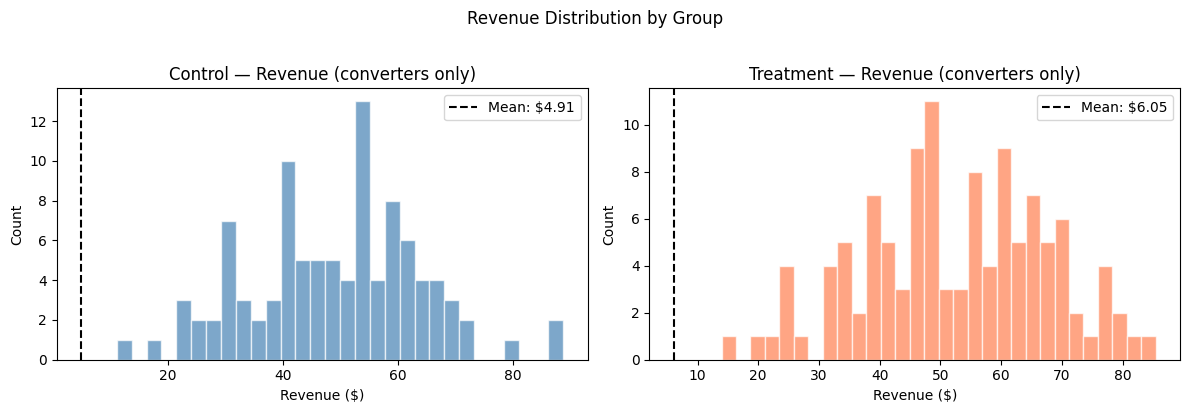

In [5]:
# Visualize revenue distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, group, color in zip(axes, ['control', 'treatment'], ['steelblue', 'coral']):
    data = df[df['group'] == group]['revenue']
    data_nonzero = data[data > 0]
    ax.hist(data_nonzero, bins=30, color=color, alpha=0.7, edgecolor='white')
    ax.axvline(data.mean(), color='black', linestyle='--', label=f'Mean: ${data.mean():.2f}')
    ax.set_title(f'{group.capitalize()} — Revenue (converters only)')
    ax.set_xlabel('Revenue ($)')
    ax.set_ylabel('Count')
    ax.legend()

plt.suptitle('Revenue Distribution by Group', y=1.02)
plt.tight_layout()
plt.show()

---
## Section 6: Statistical vs Practical Significance

A result can be **statistically significant** but **practically meaningless** — especially with large samples, even tiny differences become significant.

**Effect size** (Cohen's d) measures the magnitude of the difference in standard deviation units:
$$d = \frac{|\mu_A - \mu_B|}{s_{pooled}}$$

Interpretation: d = 0.2 (small), 0.5 (medium), 0.8 (large)

In [6]:
mean_a = ctrl['revenue'].mean()
mean_b = treat['revenue'].mean()
std_pooled = np.sqrt(
    (ctrl['revenue'].std()**2 + treat['revenue'].std()**2) / 2
)
cohen_d = abs(mean_a - mean_b) / std_pooled

print('Effect Size — Revenue')
print(f'  Cohen\'s d: {cohen_d:.4f}')
print()
print('Key question: is the effect large enough to be worth the engineering cost,')
print('rollout risk, and operational overhead of shipping the new design?')

Effect Size — Revenue
  Cohen's d: 0.0692

Key question: is the effect large enough to be worth the engineering cost,
rollout risk, and operational overhead of shipping the new design?


---
## Section 7: Common Pitfalls

- **Peeking**: checking results while the experiment is still running and stopping early when p < 0.05 inflates your Type I error rate. Run the test for the planned duration, commit to a sample size upfront.

- **Multiple testing**: testing 10 metrics at α = 0.05 gives a ~40% chance of at least one false positive. Apply corrections (Bonferroni: α / number of tests) or pre-register your primary metric.

- **Novelty effect**: users interact differently with new features just because they're new. Short experiments on high-novelty changes (new UI) can show an inflated treatment effect that fades over time.

- **Simpson's paradox**: an aggregate trend can reverse within subgroups. Always segment your results — if conversion improved overall but dropped for mobile users, you need to know.

- **Interference**: if users in A and B can influence each other (social networks, marketplaces), the independence assumption breaks. Consider cluster randomization.

In [7]:
# Multiple testing — Bonferroni correction
metrics    = ['conversion', 'revenue', 'time_on_page', 'bounce_rate', 'pages_per_session']
n_tests    = len(metrics)
alpha_raw  = 0.05
alpha_bonf = alpha_raw / n_tests

print(f'Testing {n_tests} metrics at α = {alpha_raw}')
print(f'P(at least one false positive) ≈ {1 - (1 - alpha_raw)**n_tests:.2%}')
print()
print(f'Bonferroni correction: α / {n_tests} = {alpha_bonf:.4f}')
print(f'Use α = {alpha_bonf:.4f} per test to maintain overall Type I error rate of {alpha_raw}')

Testing 5 metrics at α = 0.05
P(at least one false positive) ≈ 22.62%

Bonferroni correction: α / 5 = 0.0100
Use α = 0.0100 per test to maintain overall Type I error rate of 0.05
